# ViT / Swin classifier

**Phase:** 1 | **Model:** Swin-B (`swin_base_patch4_window12_384`, ImageNet-22k) | **Data:** `bench/` from `02_data_prep` | **Settings:** [configs/swin_b.yaml](../../configs/swin_b.yaml)

Fine-tuned Swin-B gives one defect probability per image (no boxes). Input is 640 x 1024, the exact size of the board crops from data prep, because many defects are small and would almost vanish at the usual 224 x 224. No online augmentation, train was already augmented offline in data prep.

**Two runs, same settings:** first on gray images, then a second full run on color images, each starting from the ImageNet weights. Both trained on Kaggle (T4 x2) and the run folders were downloaded into `results/swin/pcb1/`. The train cells are left unrun here; every other cell reads the run folder (`history.csv`, `val_predictions.csv`, `test_predictions.csv`), so the numbers below are exactly the ones from the training run. Checkpoints are git-ignored.

## Steps

- [x] Load the config, data and pretrained model
- [x] Train on train, score val every epoch, keep the best epoch
- [x] Pick the threshold on val only
- [x] Run on test once with the val threshold
- [x] Gray and color runs
- [ ] Log every test image to `results/per_image/`
- [ ] Record latency (after warm-up), peak VRAM, model size

## 1. Setup

In [1]:
import os

import numpy as np
import pandas as pd
import timm
import torch
import yaml
from IPython.display import Image, display

from vision_benchmark.evaluation import best_threshold, image_metrics, recall_by_type
from vision_benchmark.models import SplitDataset, build_classifier, fit, make_loader, predict, seed_everything
from vision_benchmark.utils import plot_confusion_matrix, plot_roc_pr, plot_training_history

In [2]:
DATASET = "pcb1"

ROOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
BENCH = os.path.join(ROOT, "bench")
CFG_PATH = os.path.join(ROOT, "configs", "swin_b.yaml")
RUNS_DIR = os.path.join(ROOT, "results", "swin", DATASET)
GRAY_DIR = os.path.join(RUNS_DIR, "swin_b_gray")
COLOR_DIR = os.path.join(RUNS_DIR, "swin_b_color")

split_df = pd.read_csv(os.path.join(BENCH, "split.csv"))
print("gray run :", GRAY_DIR)
print("color run:", COLOR_DIR)

gray run : D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\swin\pcb1\swin_b_gray
color run: D:\Full AI\Projects\GitHub - Kaggle Projects\vision-model-selection-benchmark\results\swin\pcb1\swin_b_color


## 2. Config

Both runs use the same settings. `batch` is per GPU, so one step sees `batch x gpus` images, and gradients are summed over steps until `nbs` images (one weight update).

In [3]:
with open(CFG_PATH) as f:
    CFG = yaml.safe_load(f)

size = tuple(CFG["img_size"])
STEP_BATCH = CFG["batch"] * CFG["gpus"]   # images per step, split across the GPUs
ACCUM = CFG["nbs"] // STEP_BATCH         # steps per weight update
print(f"images per step: {STEP_BATCH} | steps per weight update: {ACCUM}")
pd.Series(CFG, name="value").to_frame()

images per step: 8 | steps per weight update: 2


,value
model,swin_base_patch4_window12_384.ms_in22k_ft_in1k
img_size,"[640, 1024]"
epochs,20
batch,4
gpus,2
nbs,16
lr,0.0001
weight_decay,0.05
warmup_epochs,1
drop_path_rate,0.1


## 3. GPU check

In [4]:
print("GPUs found:", torch.cuda.device_count(), "| needed for training:", CFG["gpus"])
for i in range(torch.cuda.device_count()):
    props = torch.cuda.get_device_properties(i)
    print(f"GPU {i}:", props.name, "|", round(props.total_memory / 2**30, 1), "GB")
print("torch", torch.__version__, "| timm", timm.__version__)

GPUs found: 1 | needed for training: 2
GPU 0: NVIDIA GeForce RTX 2060 SUPER | 8.0 GB
torch 2.11.0+cu130 | timm 1.0.31


## 4. Data

Same `split.csv` as every other model. Image-level labels only, boxes are not used. Gray and color have the same images and labels.

In [5]:
split_df.groupby(["split", "label"]).size().unstack().rename(columns={0: "normal", 1: "defect"}).loc[["train", "val", "test"]]

label,normal,defect
split,,
train,231,200
val,100,20
test,300,30


## 5. Model and best epoch

Pretrained weights are downloaded by timm from the Hugging Face hub. The 1000-class ImageNet head is replaced by one output (the defect logit). The model is wrapped in `DataParallel` so every step uses both GPUs.

Each epoch prints train loss, val loss, val AUROC and whether the epoch is a new best (and why) or how many epochs passed without one. Training stops after `patience` epochs without a new best.

How the best epoch (`best.pt`) is chosen:
- Until val AUROC reaches `auroc_floor` (0.98), only a higher AUROC makes a new best.
- After that AUROC is near its top and small changes are noise (with 20 val defects one pair of images moves it by 0.0005), so val loss decides too. An epoch is a new best if AUROC stays within `auroc_tol` (0.005) of its peak and val loss is at least `min_loss_drop` (5%) lower than the best epoch. A loss that falls only a little is not enough.
- A clear AUROC gain (`auroc_tol` or more) also counts, unless val loss is more than `max_loss_rise` (20%) higher: that is a model getting overconfident, not better.

## 6. Gray: train

Trains from the ImageNet weights, then scores val and test with the best epoch and saves the scores. Needs two GPUs (Kaggle T4 x2).

In [ ]:
assert torch.cuda.device_count() >= CFG["gpus"], f"config asks for {CFG['gpus']} GPUs, found {torch.cuda.device_count()}"
seed_everything(CFG["seed"])
train_ds = SplitDataset(BENCH, "train", "gray", size)
val_ds = SplitDataset(BENCH, "val", "gray", size)
test_ds = SplitDataset(BENCH, "test", "gray", size)
train_loader = make_loader(train_ds, STEP_BATCH, shuffle=True, workers=CFG["workers"], seed=CFG["seed"])
val_loader = make_loader(val_ds, STEP_BATCH * 2, shuffle=False, workers=CFG["workers"])
test_loader = make_loader(test_ds, STEP_BATCH * 2, shuffle=False, workers=CFG["workers"])

model = build_classifier(CFG["model"], size, CFG["drop_path_rate"]).cuda()
model = torch.nn.DataParallel(model, device_ids=list(range(CFG["gpus"])))
fit(model, train_loader, val_loader, CFG["epochs"], CFG["lr"], CFG["weight_decay"], ACCUM, CFG["warmup_epochs"],
    GRAY_DIR, patience=CFG["patience"], auroc_floor=CFG["auroc_floor"], auroc_tol=CFG["auroc_tol"],
    min_loss_drop=CFG["min_loss_drop"], max_loss_rise=CFG["max_loss_rise"])

In [ ]:
model.module.load_state_dict(torch.load(os.path.join(GRAY_DIR, "best.pt"), map_location="cuda"))
for name, ds, loader in [("val", val_ds, val_loader), ("test", test_ds, test_loader)]:
    scores, _, _ = predict(model, loader)
    ds.df[["image_id", "label", "defect_type", "has_small_box"]].assign(score=scores).to_csv(
        os.path.join(GRAY_DIR, f"{name}_predictions.csv"), index=False)

## 7. Gray: training results

Files saved by the run:

In [6]:
sorted(os.listdir(GRAY_DIR))

['best.pt',
 'history.csv',
 'test_confusion_matrix.png',
 'test_predictions.csv',
 'test_roc_pr.png',
 'train_batch.png',
 'training_history.png',
 'val_confusion_matrix.png',
 'val_predictions.csv',
 'val_roc_pr.png']

One row per epoch (`best` says why an epoch became the new best, empty = no improvement):

In [7]:
history_gray = pd.read_csv(os.path.join(GRAY_DIR, "history.csv")).fillna("")
history_gray

,epoch,train_loss,val_loss,val_auroc,lr,time_s,best
0,1,0.508925,0.303059,0.93950,0.000100,76.417771,AUROC up
1,2,0.486237,0.235014,0.95000,0.000099,71.497190,AUROC up
2,3,0.160950,0.162685,0.98450,0.000097,72.281812,AUROC reached 0.98
3,4,0.099046,0.079374,0.99200,0.000094,72.207756,AUROC up
4,5,0.022443,0.245020,0.98650,0.000089,70.411267,
5,6,0.012221,0.194327,0.98650,0.000084,70.013076,
6,7,0.002896,0.222018,0.98225,0.000077,69.757401,
7,8,0.000866,0.202788,0.98750,0.000070,70.366544,
8,9,0.003851,0.296145,0.98450,0.000062,69.488439,


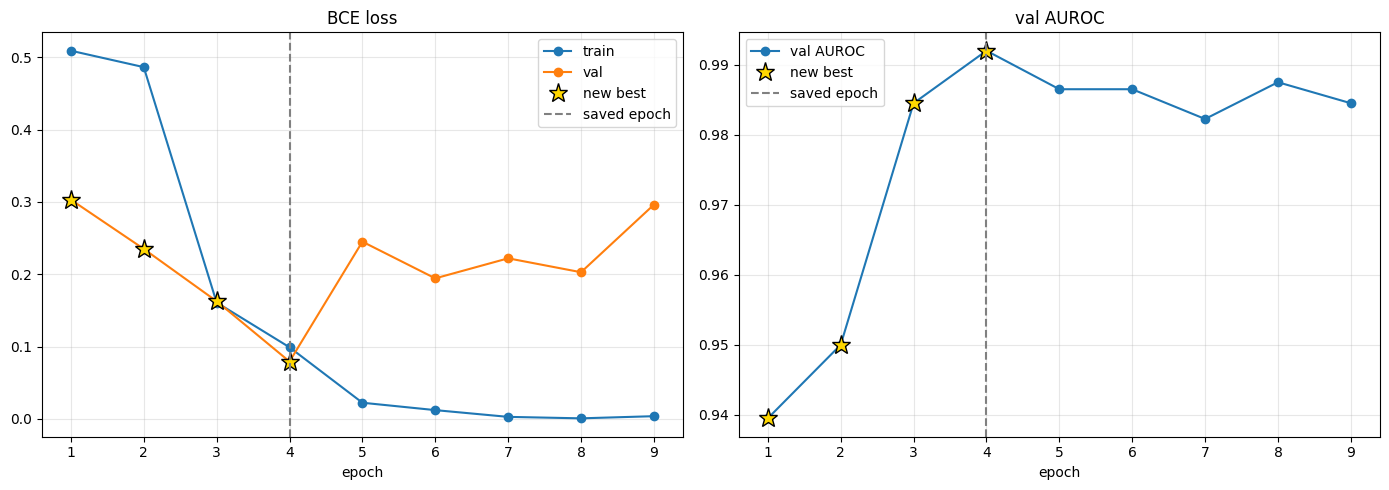

In [8]:
plot_training_history(history_gray)

A train batch as the model gets it (normalization undone for display):

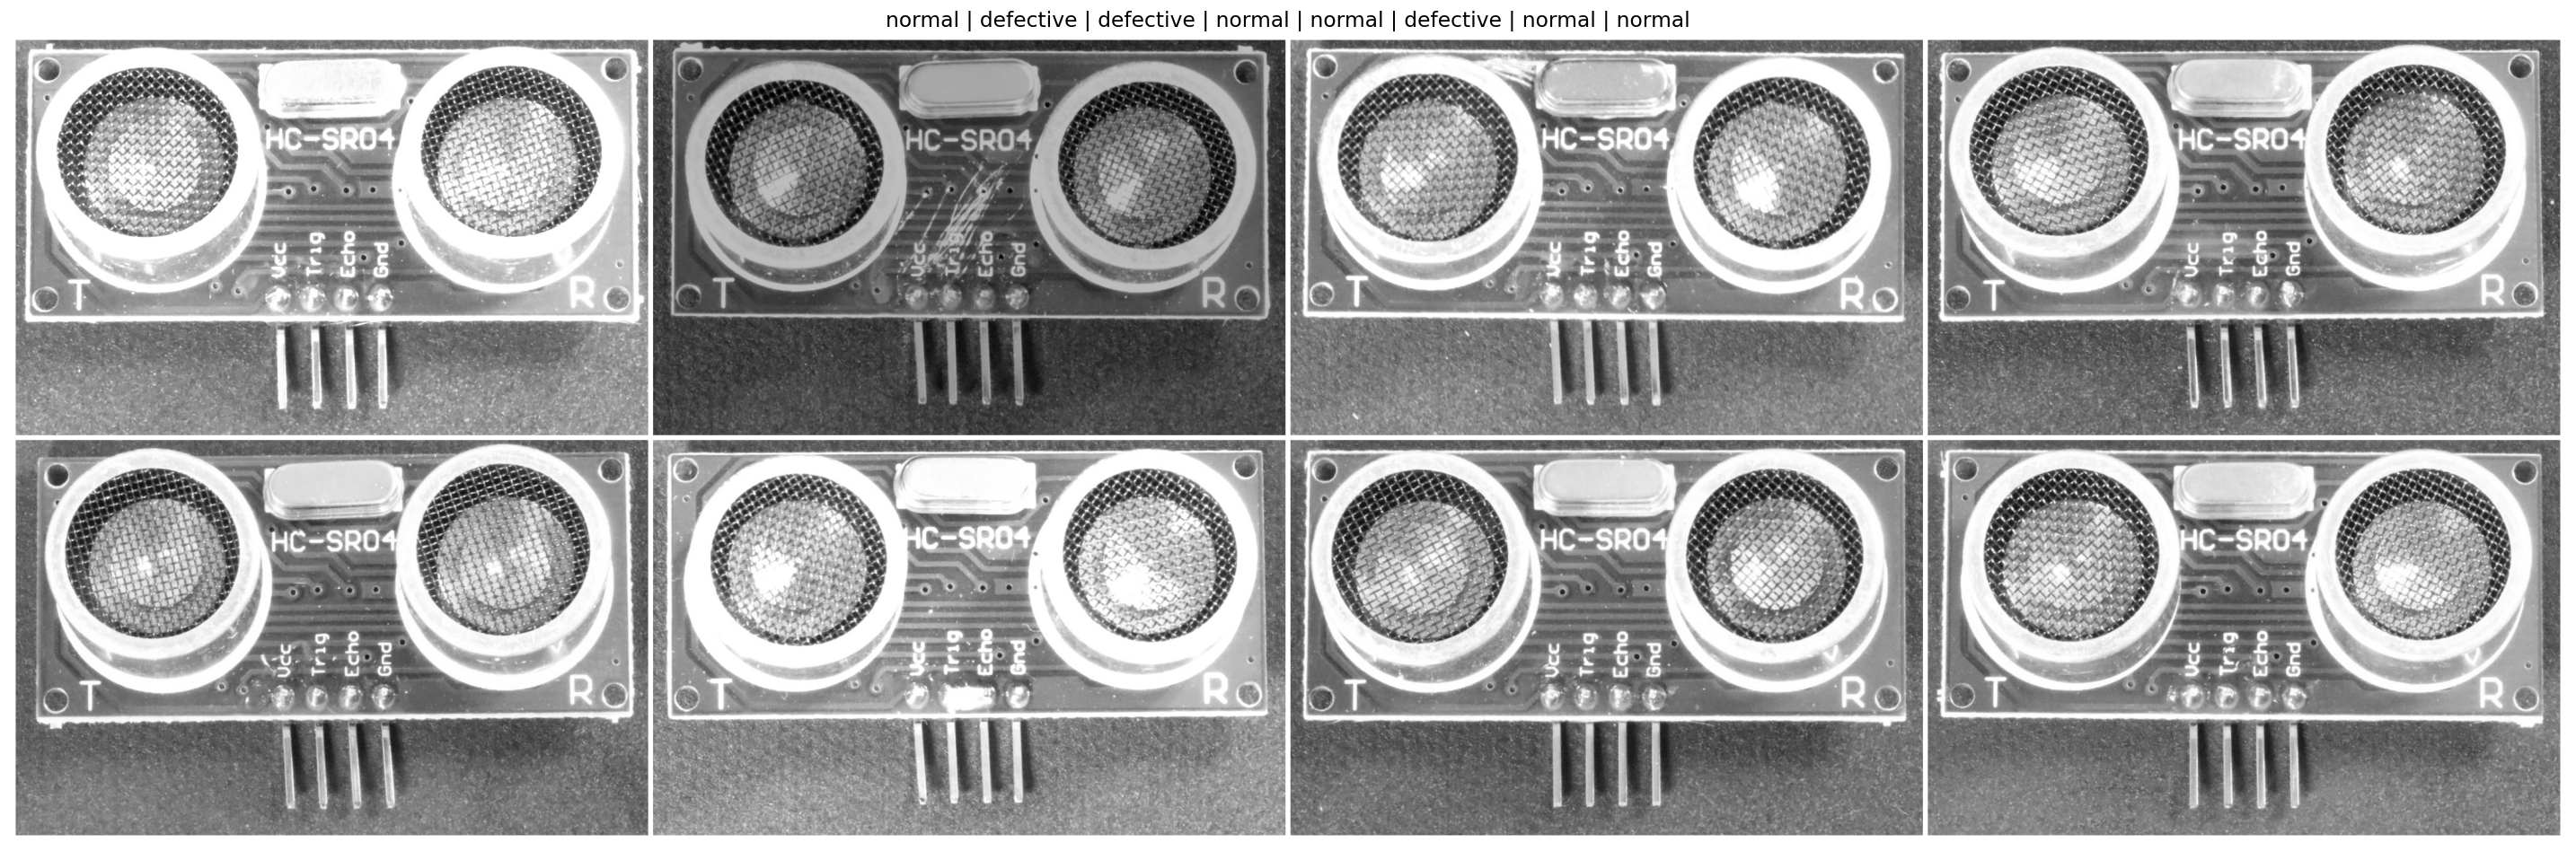

In [9]:
display(Image(filename=os.path.join(GRAY_DIR, "train_batch.png")))

## 8. Gray: val (best epoch)

The threshold is picked here on val (best F1) and reused unchanged on test.

In [10]:
val_gray = pd.read_csv(os.path.join(GRAY_DIR, "val_predictions.csv"))
THRESHOLD_GRAY = best_threshold(val_gray["label"], val_gray["score"])
pd.Series(image_metrics(val_gray["label"], val_gray["score"], THRESHOLD_GRAY), name="val").to_frame()

,val
auroc,0.992000
ap,0.958144
threshold,0.377655
accuracy,0.983333
precision,0.950000
recall,0.950000
f1,0.950000
tp,19.000000
fp,1.000000
fn,1.000000


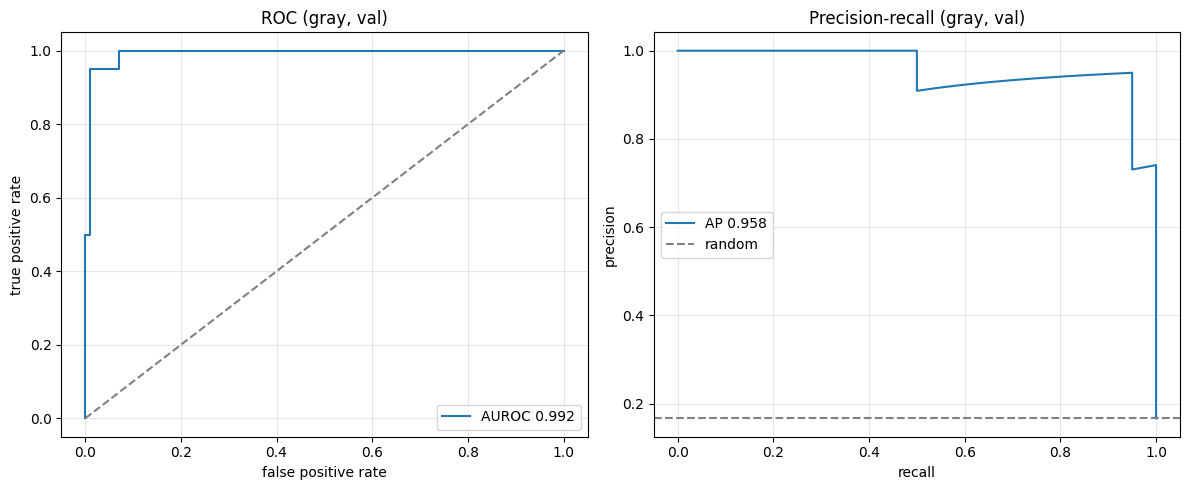

In [11]:
plot_roc_pr(val_gray["label"], val_gray["score"], title="(gray, val)")

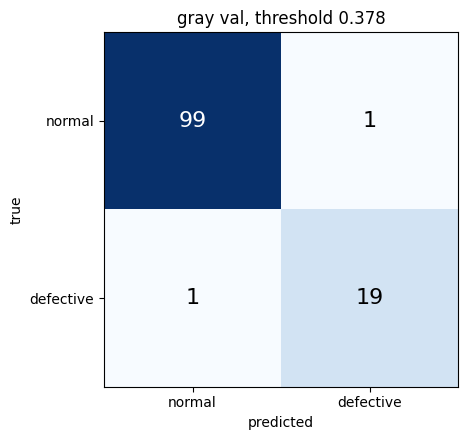

In [12]:
plot_confusion_matrix(val_gray["label"], val_gray["score"], THRESHOLD_GRAY, title="gray val,")

Highest scores on val:

In [13]:
val_gray.sort_values("score", ascending=False).head(25)

,image_id,label,defect_type,has_small_box,score,pred
114,pcb1_defect_068,1,melt,True,0.998821,1
101,pcb1_defect_005,1,bent,False,0.998770,1
113,pcb1_defect_066,1,melt,False,0.997859,1
100,pcb1_defect_002,1,bent,False,0.992539,1
110,pcb1_defect_059,1,missing,False,0.991587,1
102,pcb1_defect_016,1,melt,False,0.990102,1
109,pcb1_defect_058,1,missing,False,0.989511,1
104,pcb1_defect_025,1,melt,False,0.982288,1
119,pcb1_defect_097,1,"melt,scratch",True,0.962673,1
111,pcb1_defect_061,1,melt,False,0.952662,1


## 9. Gray: test (val threshold)

Scored once with the threshold picked on val. Changing the threshold after looking at test makes the test score optimistic, so the number to report is this one.

In [14]:
test_gray = pd.read_csv(os.path.join(GRAY_DIR, "test_predictions.csv"))
test_gray["pred"] = (test_gray["score"] >= THRESHOLD_GRAY).astype(int)
test_gray["outcome"] = np.where(test_gray["label"] == 1, np.where(test_gray["pred"] == 1, "TP", "FN"),
                           np.where(test_gray["pred"] == 1, "FP", "TN"))
pd.Series(image_metrics(test_gray["label"], test_gray["score"], THRESHOLD_GRAY), name="test").to_frame()

,test
auroc,0.986778
ap,0.885405
threshold,0.377655
accuracy,0.966667
precision,0.787879
recall,0.866667
f1,0.825397
tp,26.000000
fp,7.000000
fn,4.000000


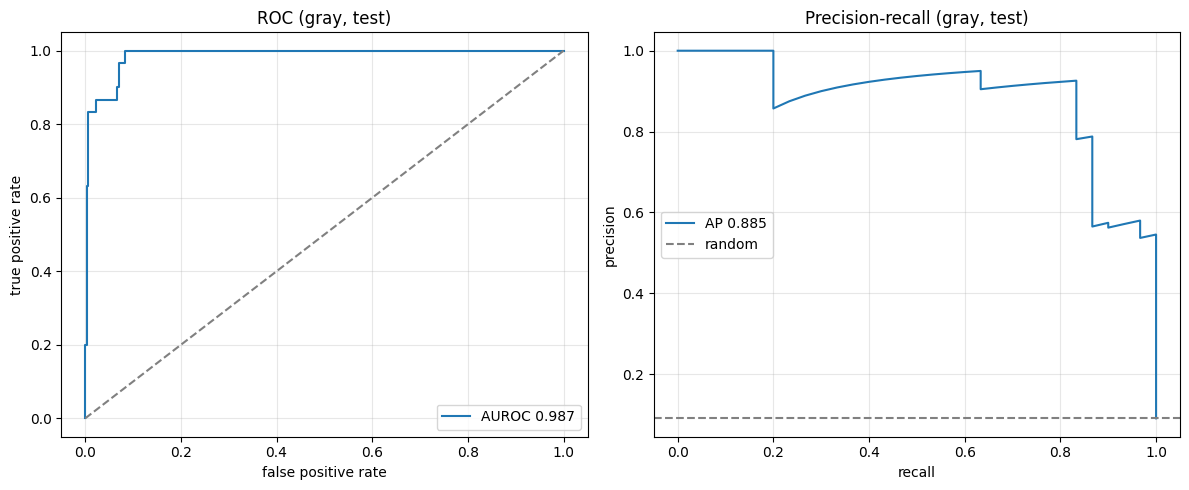

In [15]:
plot_roc_pr(test_gray["label"], test_gray["score"], title="(gray, test)")

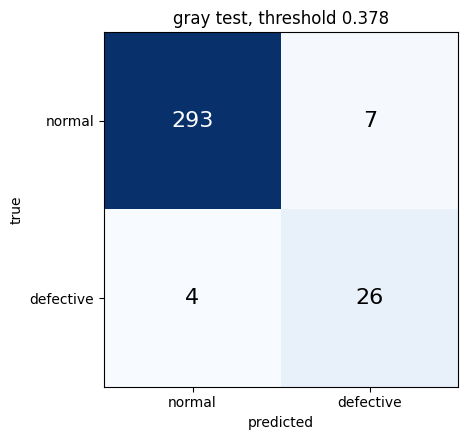

In [16]:
plot_confusion_matrix(test_gray["label"], test_gray["score"], THRESHOLD_GRAY, title="gray test,")

Found and missed defective test images per defect type and for images with a small box:

In [17]:
recall_by_type(test_gray)

outcome,TP,FN,recall
defect_type = bent,2,0,1.000
defect_type = melt,17,2,0.895
"defect_type = melt,scratch",1,0,1.000
defect_type = missing,6,0,1.000
defect_type = scratch,0,2,0.000
has_small_box = False,19,4,0.826
has_small_box = True,7,0,1.000


Missed defects (FN):

In [18]:
test_gray[test_gray["outcome"] == "FN"].sort_values("score")

,image_id,label,defect_type,has_small_box,score,pred,outcome
329,pcb1_defect_088,1,scratch,False,0.035079,0,FN
328,pcb1_defect_086,1,scratch,False,0.083441,0,FN
302,pcb1_defect_015,1,melt,False,0.092360,0,FN
326,pcb1_defect_078,1,melt,False,0.101589,0,FN


False alarms: normal test images with the highest scores:

In [19]:
test_gray[test_gray["label"] == 0].sort_values("score", ascending=False).head(10)

,image_id,label,defect_type,has_small_box,score,pred,outcome
252,pcb1_normal_0829,0,normal,False,0.996406,1,FP
242,pcb1_normal_0801,0,normal,False,0.963643,1,FP
236,pcb1_normal_0790,0,normal,False,0.622287,1,FP
208,pcb1_normal_0672,0,normal,False,0.604341,1,FP
205,pcb1_normal_0660,0,normal,False,0.586108,1,FP
220,pcb1_normal_0731,0,normal,False,0.415077,1,FP
245,pcb1_normal_0805,0,normal,False,0.414662,1,FP
243,pcb1_normal_0803,0,normal,False,0.328637,0,TN
203,pcb1_normal_0651,0,normal,False,0.233008,0,TN
197,pcb1_normal_0635,0,normal,False,0.224225,0,TN


## 10. Color: train

Trains from the ImageNet weights, not from the gray model, so the two runs do not depend on each other, then scores val and test with the best epoch and saves the scores. Needs two GPUs (Kaggle T4 x2).

In [ ]:
assert torch.cuda.device_count() >= CFG["gpus"], f"config asks for {CFG['gpus']} GPUs, found {torch.cuda.device_count()}"
seed_everything(CFG["seed"])
train_ds = SplitDataset(BENCH, "train", "color", size)
val_ds = SplitDataset(BENCH, "val", "color", size)
test_ds = SplitDataset(BENCH, "test", "color", size)
train_loader = make_loader(train_ds, STEP_BATCH, shuffle=True, workers=CFG["workers"], seed=CFG["seed"])
val_loader = make_loader(val_ds, STEP_BATCH * 2, shuffle=False, workers=CFG["workers"])
test_loader = make_loader(test_ds, STEP_BATCH * 2, shuffle=False, workers=CFG["workers"])

model = build_classifier(CFG["model"], size, CFG["drop_path_rate"]).cuda()
model = torch.nn.DataParallel(model, device_ids=list(range(CFG["gpus"])))
fit(model, train_loader, val_loader, CFG["epochs"], CFG["lr"], CFG["weight_decay"], ACCUM, CFG["warmup_epochs"],
    COLOR_DIR, patience=CFG["patience"], auroc_floor=CFG["auroc_floor"], auroc_tol=CFG["auroc_tol"],
    min_loss_drop=CFG["min_loss_drop"], max_loss_rise=CFG["max_loss_rise"])

In [ ]:
model.module.load_state_dict(torch.load(os.path.join(COLOR_DIR, "best.pt"), map_location="cuda"))
for name, ds, loader in [("val", val_ds, val_loader), ("test", test_ds, test_loader)]:
    scores, _, _ = predict(model, loader)
    ds.df[["image_id", "label", "defect_type", "has_small_box"]].assign(score=scores).to_csv(
        os.path.join(COLOR_DIR, f"{name}_predictions.csv"), index=False)

## 11. Color: training results

Files saved by the run:

In [20]:
sorted(os.listdir(COLOR_DIR))

['best.pt',
 'history.csv',
 'test_confusion_matrix.png',
 'test_predictions.csv',
 'test_roc_pr.png',
 'train_batch.png',
 'training_history.png',
 'val_confusion_matrix.png',
 'val_predictions.csv',
 'val_roc_pr.png']

One row per epoch (`best` says why an epoch became the new best, empty = no improvement):

In [21]:
history_color = pd.read_csv(os.path.join(COLOR_DIR, "history.csv")).fillna("")
history_color

,epoch,train_loss,val_loss,val_auroc,lr,time_s,best
0,1,0.544103,0.462543,0.9330,0.000100,76.009997,AUROC up
1,2,0.238231,0.398170,0.9665,0.000099,72.551422,AUROC up
2,3,0.114861,0.289754,0.9850,0.000097,71.383759,AUROC reached 0.98
3,4,0.033649,0.192303,0.9845,0.000094,70.961267,"val loss down 33.6%, AUROC held"
4,5,0.021893,0.249096,0.9795,0.000089,70.522046,
5,6,0.004813,0.238128,0.9810,0.000084,70.135250,
6,7,0.000569,0.342877,0.9855,0.000077,69.464093,
7,8,0.000377,0.244025,0.9885,0.000070,69.429053,
8,9,0.000365,0.208983,0.9875,0.000062,69.662052,


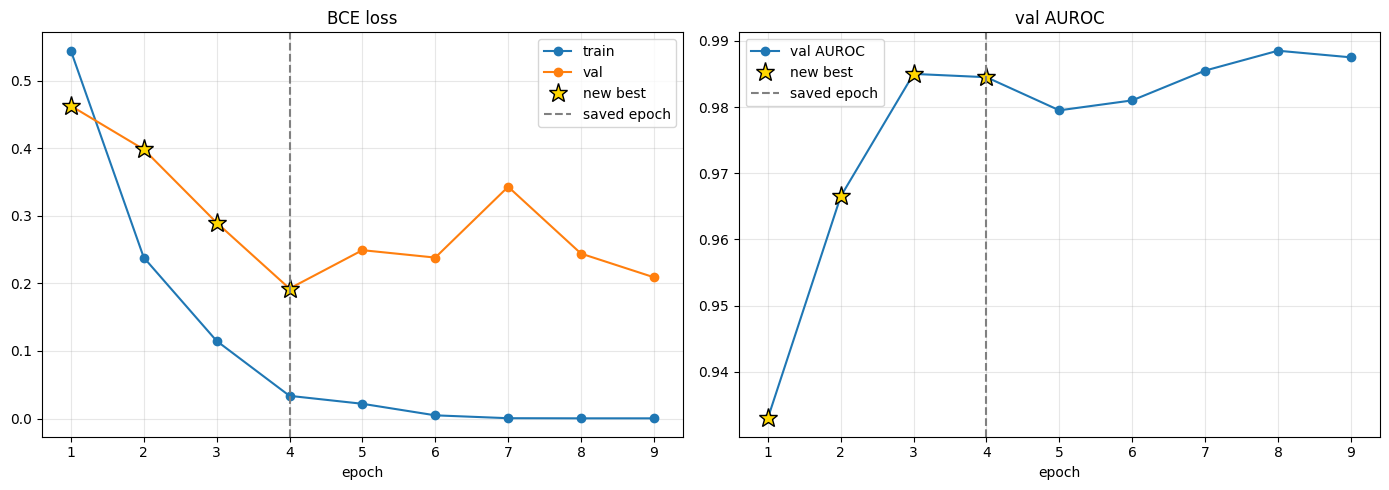

In [22]:
plot_training_history(history_color)

A train batch as the model gets it (normalization undone for display):

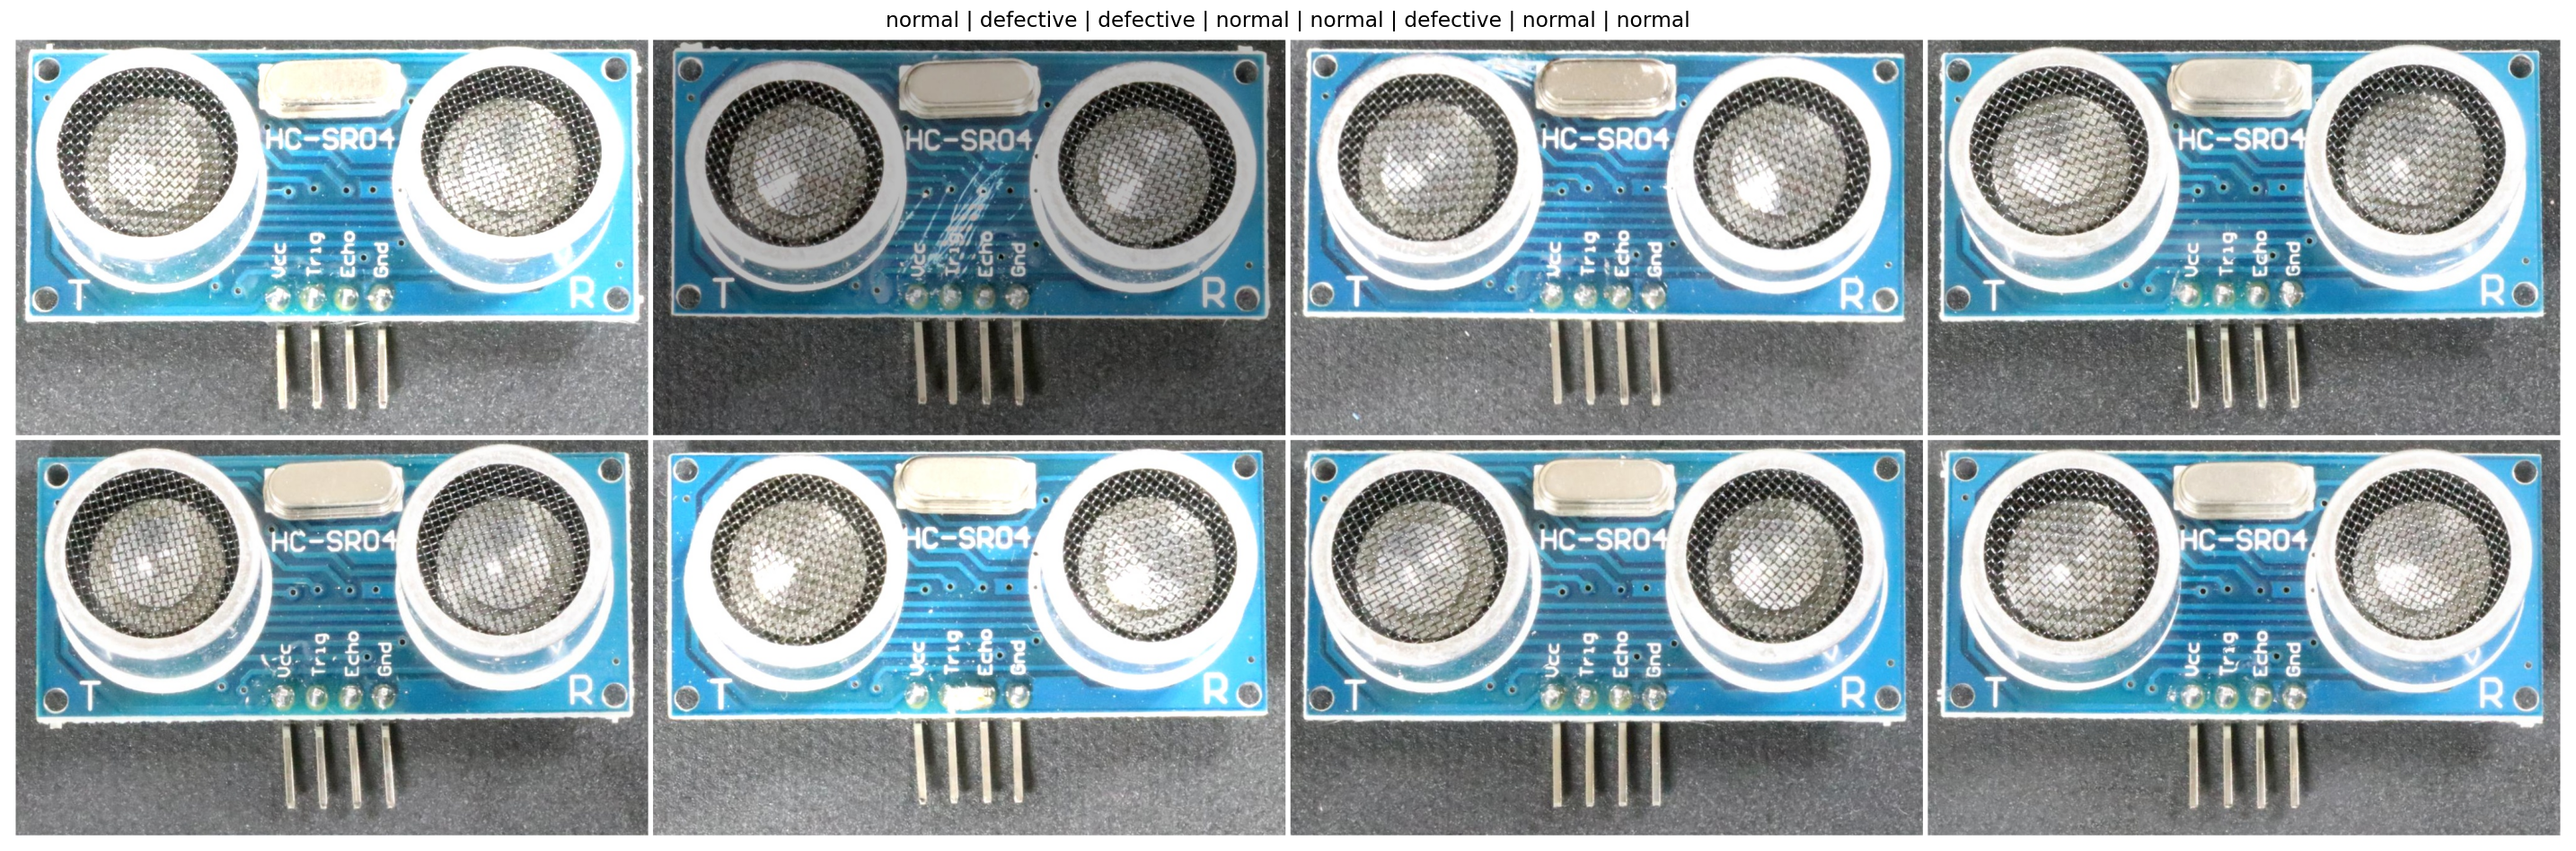

In [23]:
display(Image(filename=os.path.join(COLOR_DIR, "train_batch.png")))

## 12. Color: val (best epoch)

The threshold is picked here on val (best F1) and reused unchanged on test.

In [24]:
val_color = pd.read_csv(os.path.join(COLOR_DIR, "val_predictions.csv"))
THRESHOLD_COLOR = best_threshold(val_color["label"], val_color["score"])
pd.Series(image_metrics(val_color["label"], val_color["score"], THRESHOLD_COLOR), name="val").to_frame()

,val
auroc,0.984500
ap,0.941480
threshold,0.058993
accuracy,0.966667
precision,0.900000
recall,0.900000
f1,0.900000
tp,18.000000
fp,2.000000
fn,2.000000


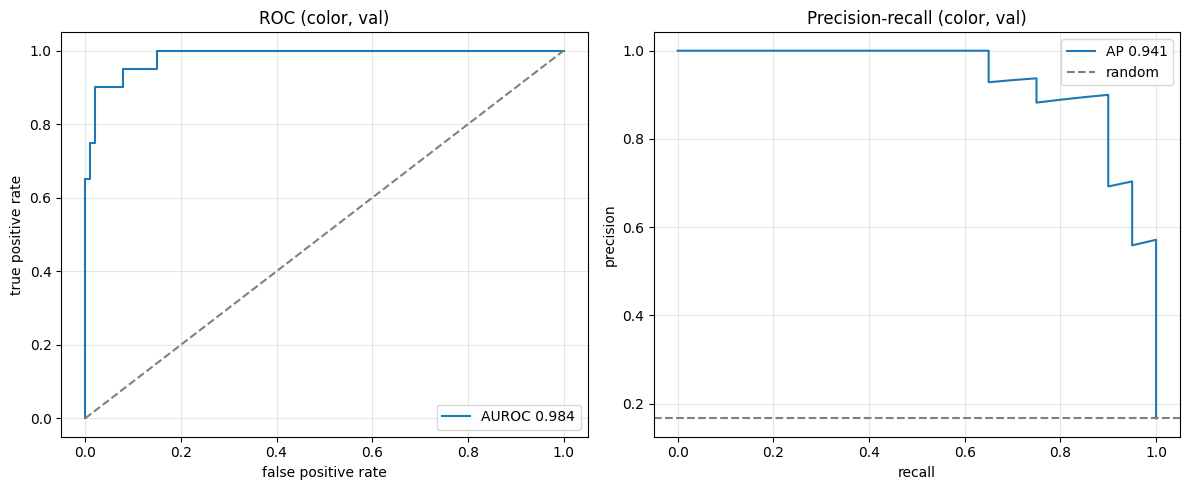

In [25]:
plot_roc_pr(val_color["label"], val_color["score"], title="(color, val)")

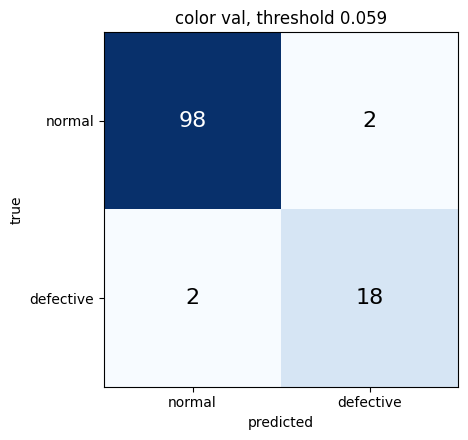

In [26]:
plot_confusion_matrix(val_color["label"], val_color["score"], THRESHOLD_COLOR, title="color val,")

Highest scores on val:

In [27]:
val_color.sort_values("score", ascending=False).head(25)

,image_id,label,defect_type,has_small_box,score,pred
100,pcb1_defect_002,1,bent,False,0.999887,1
101,pcb1_defect_005,1,bent,False,0.999842,1
114,pcb1_defect_068,1,melt,True,0.997379,1
111,pcb1_defect_061,1,melt,False,0.995898,1
103,pcb1_defect_020,1,"melt,scratch",True,0.994719,1
104,pcb1_defect_025,1,melt,False,0.974435,1
110,pcb1_defect_059,1,missing,False,0.955236,1
113,pcb1_defect_066,1,melt,False,0.950686,1
109,pcb1_defect_058,1,missing,False,0.933188,1
102,pcb1_defect_016,1,melt,False,0.913368,1


## 13. Color: test (val threshold)

Scored once with the threshold picked on val. Changing the threshold after looking at test makes the test score optimistic, so the number to report is this one.

In [28]:
test_color = pd.read_csv(os.path.join(COLOR_DIR, "test_predictions.csv"))
test_color["pred"] = (test_color["score"] >= THRESHOLD_COLOR).astype(int)
test_color["outcome"] = np.where(test_color["label"] == 1, np.where(test_color["pred"] == 1, "TP", "FN"),
                           np.where(test_color["pred"] == 1, "FP", "TN"))
pd.Series(image_metrics(test_color["label"], test_color["score"], THRESHOLD_COLOR), name="test").to_frame()

,test
auroc,0.989111
ap,0.935033
threshold,0.058993
accuracy,0.960606
precision,0.717949
recall,0.933333
f1,0.811594
tp,28.000000
fp,11.000000
fn,2.000000


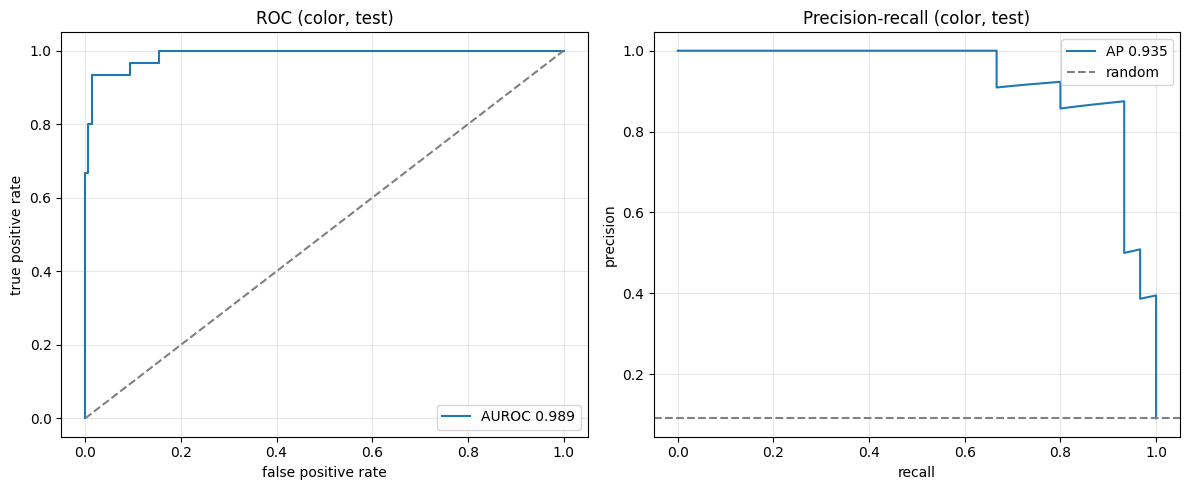

In [29]:
plot_roc_pr(test_color["label"], test_color["score"], title="(color, test)")

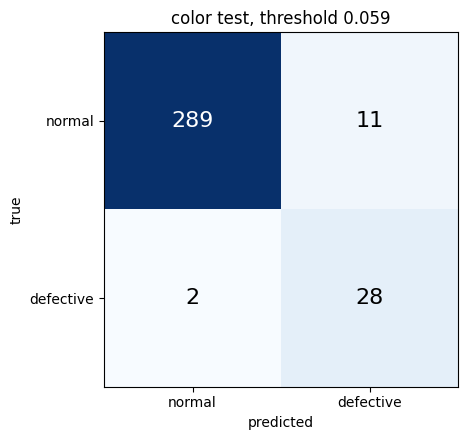

In [30]:
plot_confusion_matrix(test_color["label"], test_color["score"], THRESHOLD_COLOR, title="color test,")

Found and missed defective test images per defect type and for images with a small box:

In [31]:
recall_by_type(test_color)

outcome,TP,FN,recall
defect_type = bent,2,0,1.000
defect_type = melt,19,0,1.000
"defect_type = melt,scratch",1,0,1.000
defect_type = missing,5,1,0.833
defect_type = scratch,1,1,0.500
has_small_box = False,21,2,0.913
has_small_box = True,7,0,1.000


Missed defects (FN):

In [32]:
test_color[test_color["outcome"] == "FN"].sort_values("score")

,image_id,label,defect_type,has_small_box,score,pred,outcome
328,pcb1_defect_086,1,scratch,False,0.003795,0,FN
312,pcb1_defect_042,1,missing,False,0.016657,0,FN


False alarms: normal test images with the highest scores:

In [33]:
test_color[test_color["label"] == 0].sort_values("score", ascending=False).head(10)

,image_id,label,defect_type,has_small_box,score,pred,outcome
252,pcb1_normal_0829,0,normal,False,0.840390,1,FP
242,pcb1_normal_0801,0,normal,False,0.831280,1,FP
236,pcb1_normal_0790,0,normal,False,0.545649,1,FP
237,pcb1_normal_0792,0,normal,False,0.421611,1,FP
251,pcb1_normal_0823,0,normal,False,0.175538,1,FP
206,pcb1_normal_0664,0,normal,False,0.140336,1,FP
245,pcb1_normal_0805,0,normal,False,0.090735,1,FP
203,pcb1_normal_0651,0,normal,False,0.073430,1,FP
202,pcb1_normal_0648,0,normal,False,0.068413,1,FP
186,pcb1_normal_0611,0,normal,False,0.068164,1,FP


## 14. Gray vs color

Image-level metrics of both runs, each at its own val threshold:

In [34]:
runs = {
    "gray val": image_metrics(val_gray["label"], val_gray["score"], THRESHOLD_GRAY),
    "color val": image_metrics(val_color["label"], val_color["score"], THRESHOLD_COLOR),
    "gray test": image_metrics(test_gray["label"], test_gray["score"], THRESHOLD_GRAY),
    "color test": image_metrics(test_color["label"], test_color["score"], THRESHOLD_COLOR),
}
# object Series keep the counts as whole numbers
pd.concat({k: pd.Series({m: round(v, 3) if isinstance(v, float) else v for m, v in r.items()}, dtype=object)
           for k, r in runs.items()}, axis=1)

,gray val,color val,gray test,color test
auroc,0.992,0.984,0.987,0.989
ap,0.958,0.941,0.885,0.935
threshold,0.378,0.059,0.378,0.059
accuracy,0.983,0.967,0.967,0.961
precision,0.95,0.9,0.788,0.718
recall,0.95,0.9,0.867,0.933
f1,0.95,0.9,0.825,0.812
tp,19,18,26,28
fp,1,2,7,11
fn,1,2,4,2


Test recall per defect type side by side:

In [35]:
pd.concat({"gray": recall_by_type(test_gray), "color": recall_by_type(test_color)}, axis=1)

gray           color          
outcome                      TP FN recall    TP FN recall
defect_type = bent            2  0  1.000     2  0  1.000
defect_type = melt           17  2  0.895    19  0  1.000
defect_type = melt,scratch    1  0  1.000     1  0  1.000
defect_type = missing         6  0  1.000     5  1  0.833
defect_type = scratch         0  2  0.000     1  1  0.500
has_small_box = False        19  4  0.826    21  2  0.913
has_small_box = True          7  0  1.000     7  0  1.000

## Findings

- **Both runs reached val AUROC 0.98 at epoch 3 and saved epoch 4** (gray: AUROC up to 0.992; color: AUROC held at 0.985 with val loss down 34%). After that train loss went to almost 0 while val loss rose: the model started memorizing train. Early stopping ended both runs at epoch 9.
- **Test, gray:** AUROC 0.987, 26 of 30 defects found, 7 false alarms in 300 normal boards (F1 0.825). Misses: both scratches and 2 melts.
- **Test, color:** AUROC 0.989, 28 of 30 found, 11 false alarms (F1 0.812). Color finds every melt; it misses one scratch and one missing part, and raises more false alarms at its val threshold.
- **Against YOLO26-S on the same test images:** YOLO reached AUROC 0.912 (gray) and 0.946 (color) with 25 and 26 defects found. Swin ranks images much better, but it gives no box showing where the defect is.
- The same three normal boards (`pcb1_normal_0829`, `0801`, `0790`) are the top false alarms in both runs, so they are worth a look before blaming the model.
- Val has only 20 defects, so one image moves val recall by 5%. The val thresholds (0.38 gray, 0.06 color) are rough because of that.

## Next

- Per-image log, latency, VRAM and model size.